# Projeto Interdisciplinar — ASA | Entrega 2
## Agente de Monitoramento de Risco de Evasão · modelo v2

Este notebook evolui a baseline da Entrega 1 (Regressão Logística, AUC 0,82, Recall 77%) e documenta:

1. a **mesma limpeza e o mesmo split** da E1 (comparação justa);
2. a comparação **Regressão Logística × Random Forest × XGBoost** com validação cruzada estratificada e busca de hiperparâmetros;
3. calibração de probabilidades, **ajuste de limiar pela capacidade de atendimento** e recalibração das faixas Verde/Amarelo/Vermelho;
4. **equidade** por subgrupo e a variante sem Sexo e Estado Civil;
5. **explicabilidade** por aluno no formato `Fator` do contrato da API;
6. **análise de erros**;
7. a escolha final, salva em `ml/artifacts/`.

Toda a lógica está nos módulos `ml/risco/`, `ml/treinar.py` e `ml/avaliar.py`; o notebook chama essas funções e comenta os resultados.
Os dados reais ficam em `data/` (fora do Git, LGPD). **Nenhuma célula exibe linhas individuais**: só agregados, e subgrupos com menos de 30 alunos são suprimidos.

In [1]:
import os, sys, json
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import Image, display, Markdown

ML = Path.cwd() if (Path.cwd() / "treinar.py").exists() else Path.cwd() / "ml"
sys.path.insert(0, str(ML))
EVID = ML.parent / "docs" / "evidencias"
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

import warnings; warnings.filterwarnings("ignore")
from risco import dados
import treinar, avaliar
from risco.modelo import RiskModel
print("Base real:", dados.caminho_base().parent.name + "/" + dados.ARQUIVO_BASE)

Base real: data/base_unificada_asa-final.csv


## 1. Limpeza (idêntica à Entrega 1)

- **7 alunos duplicados** (14 linhas com o mesmo `ID_ALUNO` e valores idênticos): mantida a primeira ocorrência.
- **`media_notas` > 100** (2 registros): capping em 100.
- **`atraso_medio_dias` < −100 dias** (32 registros): apenas **sinalizados** (`flag_atraso_atipico`), não removidos, como no relatório da E1.

Split 75/25 estratificado com `random_state=42`, o mesmo da E1. O teste (3.209 alunos) só é usado para reportar números finais; toda escolha é feita com validação cruzada no treino.

In [2]:
df, rel = dados.carregar_limpo()
treino, teste = dados.dividir(df)
print(pd.Series(rel.como_dict()).to_string())
print(f"\nTreino: {len(treino)} alunos | Teste: {len(teste)} alunos | Evasão: treino {treino.evadiu.mean():.1%}, teste {teste.evadiu.mean():.1%}")
print(f"Taxa de evasão entre os 32 sinalizados: {df.loc[df.flag_atraso_atipico, 'evadiu'].mean():.1%} (base: {df.evadiu.mean():.1%})")

linhas_brutas           12842
duplicados_removidos        7
notas_acima_100             2
atraso_sinalizado          32
linhas_finais           12835

Treino: 9626 alunos | Teste: 3209 alunos | Evasão: treino 19.6%, teste 19.6%
Taxa de evasão entre os 32 sinalizados: 12.5% (base: 19.6%)


**Leitura:** os números batem exatamente com a E1 (12.835 alunos, 9.626/3.209). Os 32 atrasos atípicos não têm evasão acima da média, então mantê-los sem tratamento não distorce o treino; seguem sinalizados para a equipe conferir a origem (provável erro de lançamento ou pagamento antecipado).

## 2. Comparação de algoritmos (validação cruzada estratificada, 5 folds)

Busca enxuta de hiperparâmetros (grade para a logística, 10–20 sorteios para as árvores), sempre com pesos para a classe minoritária (`class_weight='balanced'` / `scale_pos_weight`). A comparação usa **o mesmo conjunto de atributos da E1**. Métricas de limiar (Recall/Precisão/F1) no corte 0,5 dos modelos ainda não calibrados.

> A execução abaixo treina todos os candidatos e variantes (≈2 min em 12 núcleos).

In [3]:
R = treinar.executar(verbose=False)
cv = pd.DataFrame({treinar.NOMES[a]: {k: f"{v['media']:.3f} ± {v['dp']:.3f}" for k, v in R.cv[a].items()} for a in R.cv}).T
cv.columns = ["AUC-ROC", "PR-AUC", "Brier", "Recall", "Precisão", "F1"]
display(cv)
display(pd.DataFrame({treinar.NOMES[a]: R.params[a] for a in R.params}).T.fillna("—"))

,AUC-ROC,PR-AUC,Brier,Recall,Precisão,F1
Regressão Logística,0.835 ± 0.011,0.599 ± 0.024,0.167 ± 0.004,0.794 ± 0.016,0.420 ± 0.009,0.549 ± 0.011
Random Forest,0.938 ± 0.006,0.861 ± 0.010,0.065 ± 0.002,0.647 ± 0.017,0.902 ± 0.016,0.753 ± 0.011
XGBoost,0.935 ± 0.007,0.855 ± 0.011,0.073 ± 0.003,0.791 ± 0.020,0.746 ± 0.013,0.768 ± 0.013


,C,min_samples_leaf,max_features,max_depth,subsample,reg_lambda,n_estimators,min_child_weight,learning_rate,colsample_bytree
Regressão Logística,1.0,—,—,—,—,—,—,—,—,—
Random Forest,—,1,sqrt,—,—,—,—,—,—,—
XGBoost,—,—,—,6.0,0.8,5.0,500.0,1.0,0.03,0.7


**Leitura:** as árvores ganham da logística por **~0,10 de AUC** e quase dobram a PR-AUC (≈0,86 vs 0,60), que é a métrica mais honesta numa base com 20% de positivos. Random Forest e XGBoost empatam (diferença < 0,005, dentro do desvio entre folds).
Pela regra definida antes de olhar o teste, fica o **XGBoost**: explica cada aluno de forma exata com TreeSHAP nativo (`pred_contribs`, sem dependência extra no backend) e o artefato é dezenas de vezes menor que uma floresta de 400 árvores profundas.

### 2.1 O ganho das árvores é real ou é memorização?

`valor_total_periodo` tem valores exatos que se repetem (preço de curso/turma), e uma árvore pode decorar "este preço → esta taxa de evasão". Teste: degradar o atributo e medir a AUC (CV) do XGBoost.

In [4]:
display(pd.Series(R.robustez, name="AUC (CV)").to_frame())

,AUC (CV)
original,0.930
valor_em_decis,0.922
valor_com_ruido_5pct_dp,0.918
sem_valor,0.887


**Leitura:** com o valor em decis ou com ruído a AUC cai menos de 0,015; sem o valor, cai para ~0,89, **ainda muito acima da logística**. A vantagem vem de relações não lineares (por exemplo, o risco é alto para valores baixos de período e volta a cair para valores muito baixos), não de decorar preços.

### 2.2 Vazamento temporal e coerência das explicações

A base é um **retrato tirado depois do desfecho**. Dois sinais disso (agregados, toda a base):

In [5]:
t1 = df.groupby(pd.cut(df.pct_parcelas_em_aberto, [-0.01, 0, 0.05, 0.2, 1], labels=["0%", "até 5%", "5–20%", ">20%"]), observed=True).evadiu.agg(alunos="size", taxa_evasao="mean")
sem = (df.media_notas == 0) & (df.media_assiduidade == 0)
t2 = df.groupby(sem.map({True: "sem notas e frequência lançadas", False: "com histórico"})).evadiu.agg(alunos="size", taxa_evasao="mean")
display(t1); display(t2)
esc = R.escolha["coerencia"]
print(f"AUC CV do XGBoost livre: {esc['auc_cv_livre']:.4f} | monotônico: {esc['auc_cv_monotonico']:.4f} | custo: {esc['custo_auc']:.4f} (limite {esc['custo_maximo']})")

,alunos,taxa_evasao
pct_parcelas_em_aberto,,
0%,7643,0.254
até 5%,2255,0.106
5–20%,2489,0.107
>20%,448,0.145


,alunos,taxa_evasao
com histórico,7491,0.114
sem notas e frequência lançadas,5344,0.310


AUC CV do XGBoost livre: 0.9293 | monotônico: 0.9152 | custo: 0.0141 (limite 0.03)


**Leitura:** quem tem **0% de parcelas em aberto evade mais** (as parcelas de quem saiu são encerradas) e quem não tem nenhuma nota lançada evade 3× mais (saiu antes das avaliações). Um modelo livre aprende isso e mostraria ao atendente fatores absurdos, como "42% das parcelas em aberto → reduz o risco".

Correção adotada no modelo final:
- **`sem_historico_academico`**: nota e frequência ambas 0 passam a ser "sem lançamento" (indicador explícito), não "nota zero";
- **restrições monotônicas** no XGBoost: mais parcelas em aberto, acordo, atraso ou reprovação → risco nunca diminui; mais nota, frequência ou tendência positiva → risco nunca aumenta.

O custo é ~0,014 de AUC na CV, abaixo do limite de 0,03 que fixamos. Em troca, toda explicação tem a direção que um atendente espera. **A AUC absoluta continua otimista** por causa do retrato pós-desfecho; isso fica registrado como a principal limitação.

### 2.3 Variantes de atributos

Mesmo algoritmo e hiperparâmetros, três conjuntos: o completo da E1; **sem Sexo e Estado Civil**; e sem eles **e sem os contatos** (`total_contatos`, `dias_desde_ultimo_contato`), por causa da regra 5 (a base não separa pedidos do estudante de contatos ativos do ASA).

In [6]:
var = pd.DataFrame({n: {treinar.NOMES[a]: v["cv_auc"] for a, v in d.items()} for n, d in R.variantes.items()}).T
var.index.name = "conjunto (AUC CV)"
display(var)
print("Escolha:", {k: v for k, v in R.escolha.items() if k != 'coerencia'})

,Regressão Logística,Random Forest,XGBoost
conjunto (AUC CV),,,
completo_e1,0.835,0.938,0.934
sem_sensiveis,0.833,0.939,0.934
sem_sensiveis_sem_contatos,0.826,0.935,0.930


Escolha: {'algoritmo': 'xgboost', 'conjunto': 'sem_sensiveis_sem_contatos', 'melhor_auc_cv': 'xgboost', 'ganho_auc_cv_sobre_logistica': 0.0999, 'perda_auc_cv_vs_completo': 0.0045, 'final': 'xgboost_monotonico'}


**Leitura:** tirar Sexo e Estado Civil não muda a AUC (diferença na terceira casa). Tirar também os contatos custa ~0,005. Como a regra é aceitar o conjunto mais restrito se a perda for < 0,01, o modelo final **não usa sexo, estado civil nem contatos com o ASA**. A idade continua como entrada (relação forte e legítima com a evasão), mas **nunca aparece como fator** para o atendente.

## 3. Salvar o artefato e avaliar no teste

`treinar.salvar` grava `ml/artifacts/risco_v2.joblib` (modelo calibrado + explicador + metadados; uma auditoria automática garante que nenhuma matriz de dados do treino foi embutida) e a seção `treino` de `metrics.json`. `avaliar.executar` gera as figuras em `docs/evidencias/`, a seção `avaliacao` e o `MODEL_VERSION.json`.

In [7]:
art = treinar.salvar(R, "contrato")
M = avaliar.executar(verbose=False)
A = M["avaliacao"]
print(art["versao"], "·", art["algoritmo"], "·", art["conjunto_features"], "· limiares ativos", art["limiares"], "· recomendados", art["limiares_recomendados"])

risco-2.0.0 · XGBoost monotônico · sem_sensiveis_sem_contatos+derivadas · limiares ativos {'amarelo': 0.3, 'vermelho': 0.6} · recomendados {'amarelo': 0.1, 'vermelho': 0.6}


### 3.1 Comparação no teste (modelos calibrados)

Recall/Precisão/F1 no corte Amarelo do contrato (0,30) sobre a probabilidade calibrada


,AUC,PR-AUC,Brier,Recall,Precisão,F1,% sinalizados
Regressão Logística,0.810,0.543,0.115,0.623,0.545,0.581,0.223
Random Forest,0.929,0.823,0.071,0.761,0.746,0.753,0.200
XGBoost,0.925,0.808,0.072,0.748,0.739,0.744,0.198
XGBoost monotônico,0.913,0.755,0.083,0.758,0.635,0.691,0.233
"Baseline E1 (RL, corte 0,5)",0.820,NaN,NaN,0.771,0.418,0.542,0.361


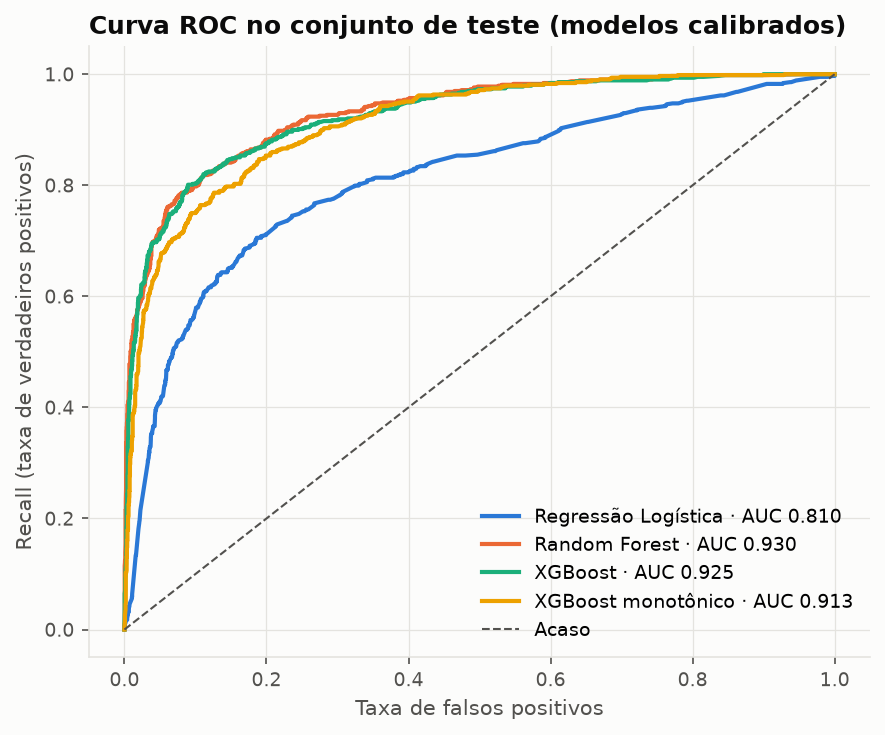

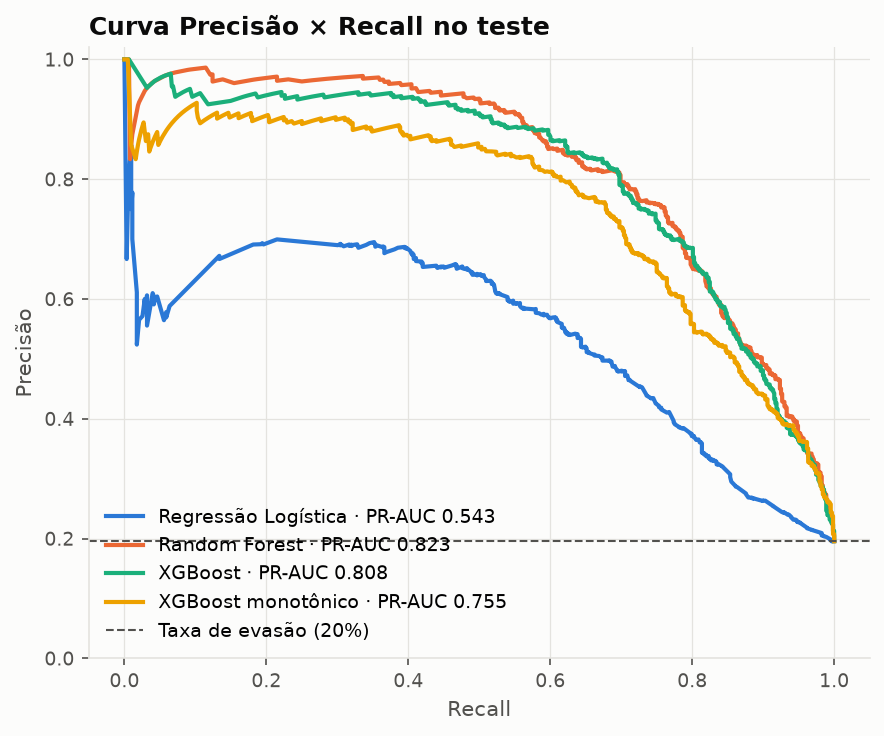

In [8]:
comp = pd.DataFrame({avaliar.g.NOME_MODELO[a]: {k: v["limiar_contrato"][k] for k in ("auc", "pr_auc", "brier", "recall", "precisao", "f1", "pct_sinalizados")}
                     for a, v in A["comparacao_teste_calibrados"].items()}).T
comp.loc["Baseline E1 (RL, corte 0,5)"] = [0.82, np.nan, np.nan, 0.7707, 0.418, 0.542, 0.3609]
comp.columns = ["AUC", "PR-AUC", "Brier", "Recall", "Precisão", "F1", "% sinalizados"]
print("Recall/Precisão/F1 no corte Amarelo do contrato (0,30) sobre a probabilidade calibrada")
display(comp)
display(Image(EVID / "risco_roc_modelos.png", width=520)); display(Image(EVID / "risco_pr_modelos.png", width=520))

**Leitura:** o XGBoost monotônico fica com AUC ≈0,91 e PR-AUC ≈0,76 no teste, contra 0,82 da baseline. No corte 0,30 ele alcança o **mesmo recall da E1 (~76%) contatando 23% dos alunos em vez de 36%**, com precisão de 64% (E1: 42%). As curvas confirmam a ordem vista na CV, sem sinal de sobreajuste.

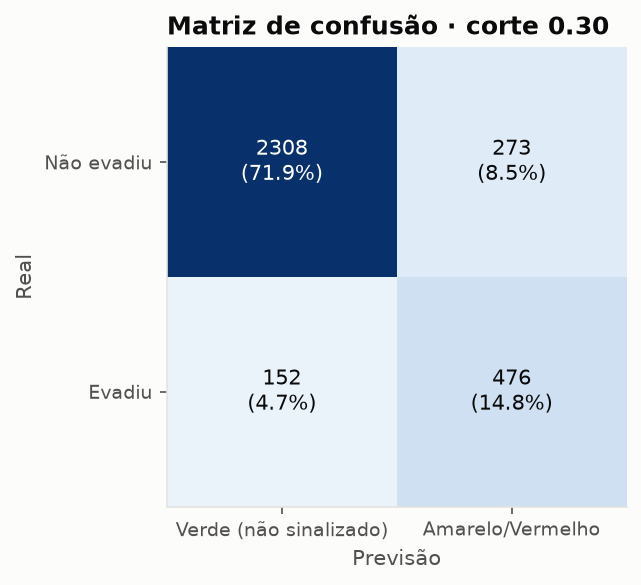

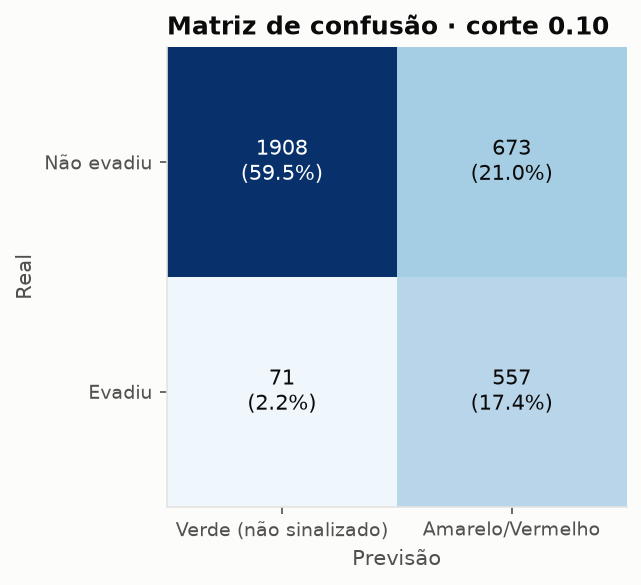

In [9]:
display(Image(EVID / "risco_matriz_confusao.png", width=380)); display(Image(EVID / "risco_matriz_confusao_recomendado.png", width=380))

### 3.2 Calibração

Os modelos são treinados com peso extra na classe "evadiu", o que **infla** as probabilidades. A calibração (isotônica ou Platt, escolhida pelo Brier fora-da-dobra no treino) corrige isso, para que "0,40" signifique "40 em cada 100 alunos parecidos evadiram".

,Brier,ECE
Sem calibrar (pesos balanceados),0.104,0.105
Calibrado (isotonic),0.083,0.015


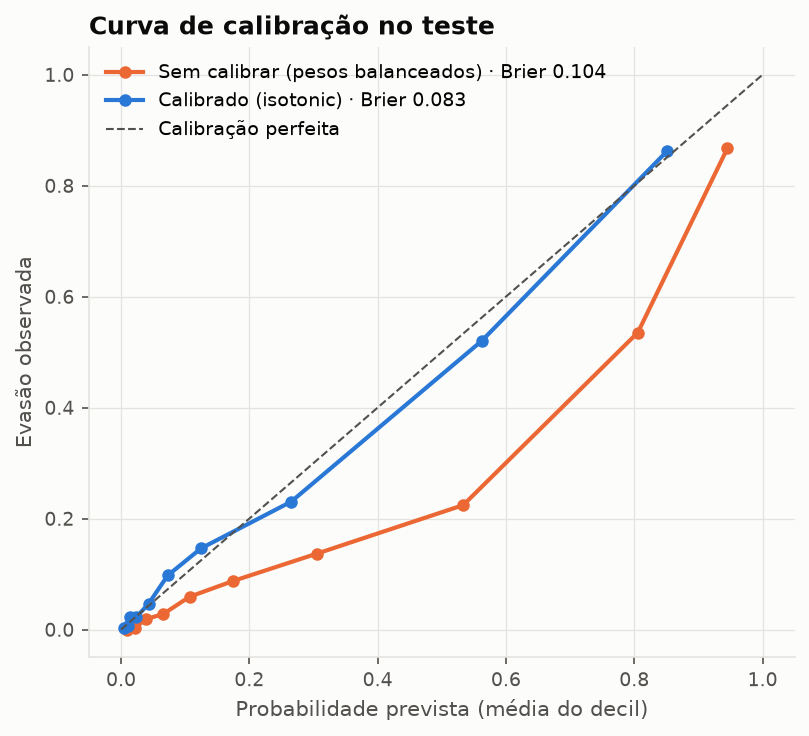

In [10]:
display(pd.DataFrame({k: {"Brier": v["brier"], "ECE": v["ece"]} for k, v in A["calibracao"].items()}).T)
display(Image(EVID / "risco_calibracao.png", width=460))

**Leitura:** a calibração isotônica reduz o erro médio de calibração (ECE) de ~0,10 para ~0,015 e o Brier de 0,104 para 0,083. A curva calibrada acompanha a diagonal; sem calibrar, o modelo superestimava o risco em todas as faixas.

## 4. Limiar de decisão pela capacidade de atendimento

A pergunta operacional não é "qual o melhor limiar?", e sim **"se a equipe do ASA consegue contatar X% dos alunos, quantas evasões ela alcança?"**. Ordenando os alunos pelo score:

,n_contatados,limiar_equivalente,recall,precisao,lift
5%,161,0.861,0.229,0.894,4.57
10%,321,0.717,0.441,0.863,4.41
15%,482,0.575,0.615,0.801,4.09
20%,642,0.389,0.707,0.692,3.53
30%,963,0.172,0.825,0.538,2.75
40%,1284,0.089,0.900,0.440,2.25


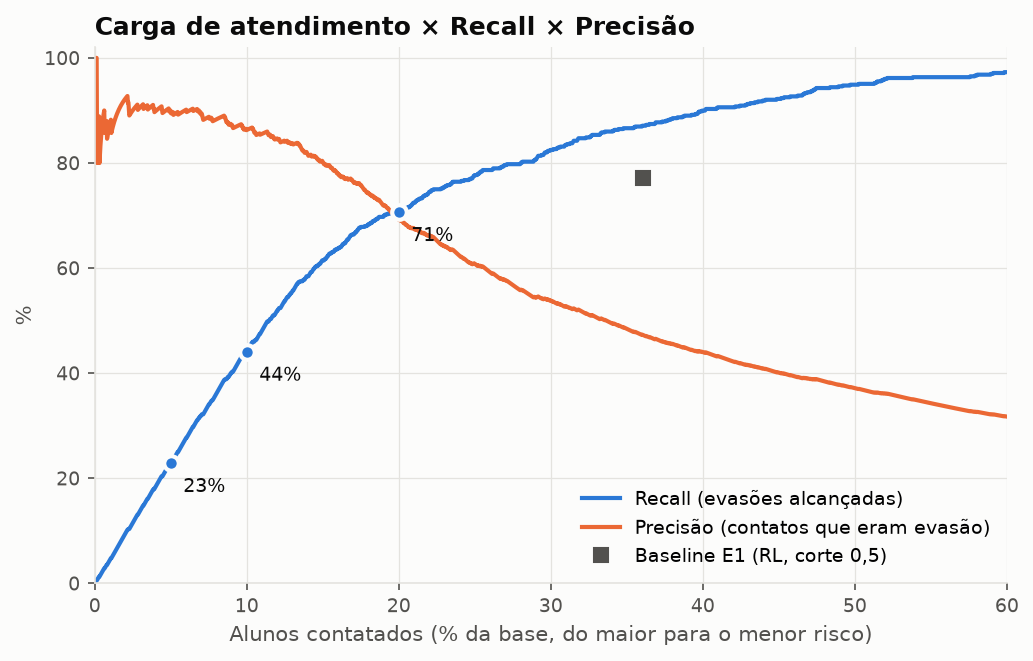

In [11]:
cap = pd.DataFrame(A["capacidade"]).set_index("pct_contatados")
cap.index = [f"{p:.0%}" for p in cap.index]
display(cap)
display(Image(EVID / "risco_capacidade.png", width=620))

**Leitura:** contatando os **5%** de maior risco, o ASA alcança ~23% das evasões com 89% de acerto; com **10%**, ~44%; com **20%**, ~71% (precisão ~69%). A baseline da E1 precisava contatar 36% dos alunos para chegar a 77%. Cada contato nos 10% do topo tem ~4,4× mais chance de ser um caso real do que um contato aleatório (lift).

### 4.1 Faixas Verde / Amarelo / Vermelho

Comparamos os cortes do contrato (0,30 / 0,60) com cortes **recalibrados pela capacidade** (Amarelo para os ~25% seguintes, Vermelho mantido em 0,60 porque já isola ~14%), definidos nas previsões fora-da-dobra do treino.

Contrato (≥0.30 / ≥0.60) · monotônica: True


,n,pct_alunos,taxa_evasao_real,prob_media_prevista
verde,2460.0,0.767,0.062,0.058
amarelo,306.0,0.095,0.369,0.448
vermelho,443.0,0.138,0.819,0.796


Recomendado (≥0.10 / ≥0.60) · monotônica: True


,n,pct_alunos,taxa_evasao_real,prob_media_prevista
verde,1979.0,0.617,0.036,0.030
amarelo,787.0,0.245,0.246,0.281
vermelho,443.0,0.138,0.819,0.796


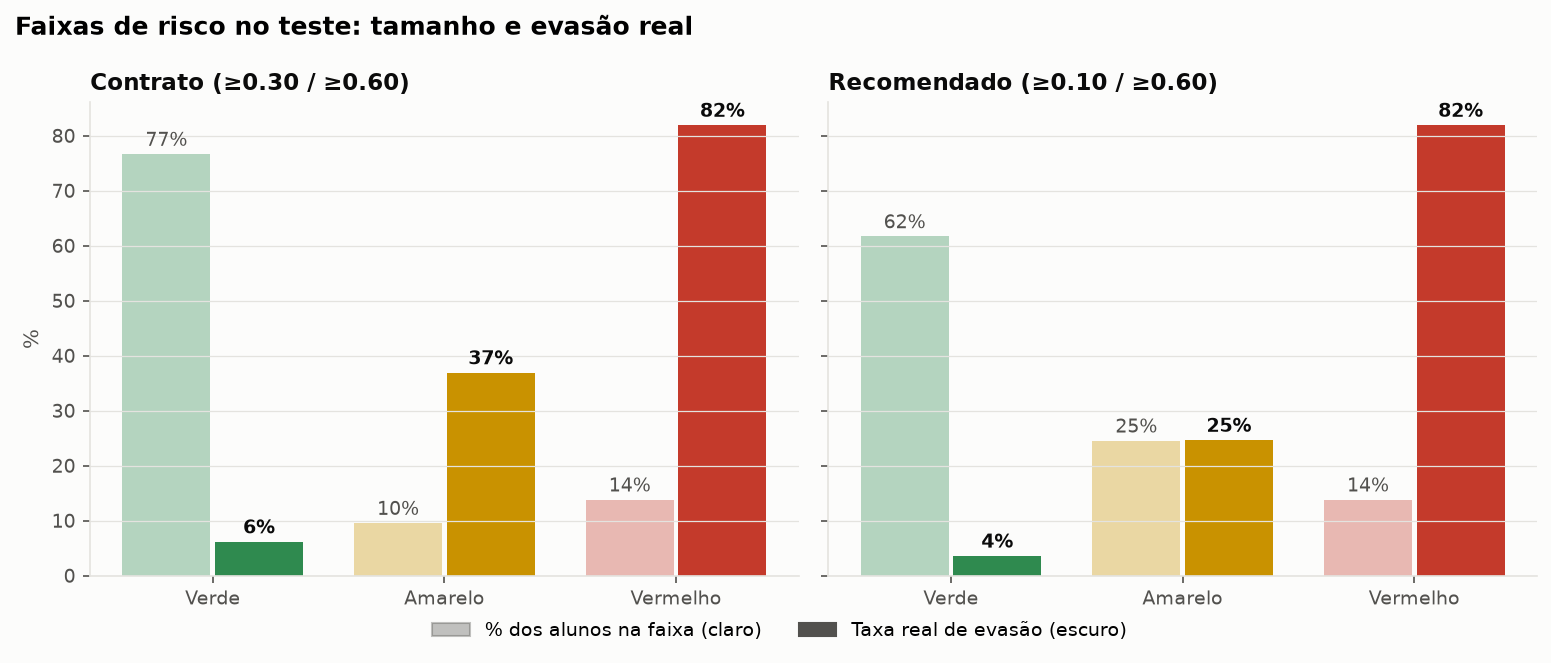

In [12]:
fx = {k: pd.DataFrame({c: v[c] for c in ("verde", "amarelo", "vermelho")}).T for k, v in A["faixas"].items()}
for k, t in fx.items():
    print(k, "· monotônica:", A["faixas"][k]["monotonica"]); display(t)
display(Image(EVID / "risco_faixas.png", width=760))

**Leitura:** nos dois esquemas a separação é forte e monotônica. Com os cortes do contrato, o Amarelo fica estreito (≈10% dos alunos) e o recall de "Amarelo ou Vermelho" é 76%. Com **Amarelo ≥ 0,10**, a distribuição fica **≈62% / 25% / 14%** (próxima da meta 60/25/15), a evasão real por faixa é **≈4% / 25% / 82%** e o recall de "Amarelo ou Vermelho" sobe para **~89%**.

**Recomendação:** adotar **Amarelo ≥ 0,10 e Vermelho ≥ 0,60** sobre a probabilidade calibrada. Como o contrato da API fixa `limiares.amarelo = 0.3` (`const`), o artefato sai **ativo com 0,30/0,60** para não quebrar o backend, e o corte recomendado fica registrado em `limiares_recomendados` (artefato e `MODEL_VERSION.json`). A troca depende de uma decisão da equipe e de uma alteração de uma linha no contrato.

## 5. Equidade

Para cada subgrupo do teste: tamanho, evasão real, **taxa de sinalização** (Amarelo ou Vermelho), **recall** e **taxa de falsos positivos**. Avaliado no corte recomendado (o de maior recall). Subgrupos com menos de 30 alunos são suprimidos.

n  taxa_evasao_real  taxa_sinalizacao  recall  taxa_falsos_positivos
atributo          grupo                                                                                            
Turno             Integral                    97             0.216             0.392   0.762                  0.289
                  Manhã                     2078             0.159             0.322   0.882                  0.215
                  Noite                     1034             0.267             0.507   0.902                  0.363
Forma de Ingresso Disciplina Isolada          39             0.000             0.077     NaN                  0.077
                  Enem                      1012             0.157             0.300   0.893                  0.190
                  Matricula Inicial          966             0.268             0.505   0.907                  0.358
                  Segunda Graduação          104             0.269             0.567   0.786                  0.487
                  Transferência              105             0.162             0.314   0.824                  0.216
                  Transferência Mesma Rede   117             0.197             0.462   0.739                  0.394
                  Vestibular                 866             0.164             0.334   0.894                  0.224
Grau Acadêmico    Bacharelado               2061             0.160             0.324   0.872                  0.220
                  Pós-Graduação             1025             0.259             0.489   0.902                  0.345
                  Tecnólogo                   94             0.266             0.489   0.960                  0.319
Faixa etária      25–29                      736             0.204             0.371   0.840                  0.251
                  30–39                      634             0.237             0.467   0.887                  0.337
                  40+                        393             0.331             0.570   0.931                  0.392
                  até 24                    1446             0.137             0.302   0.894                  0.208
Sexo              Feminino                  1683             0.186             0.352   0.885                  0.230
                  Masculino                 1407             0.207             0.415   0.887                  0.292
                  Nao informado              119             0.202             0.454   0.917                  0.337

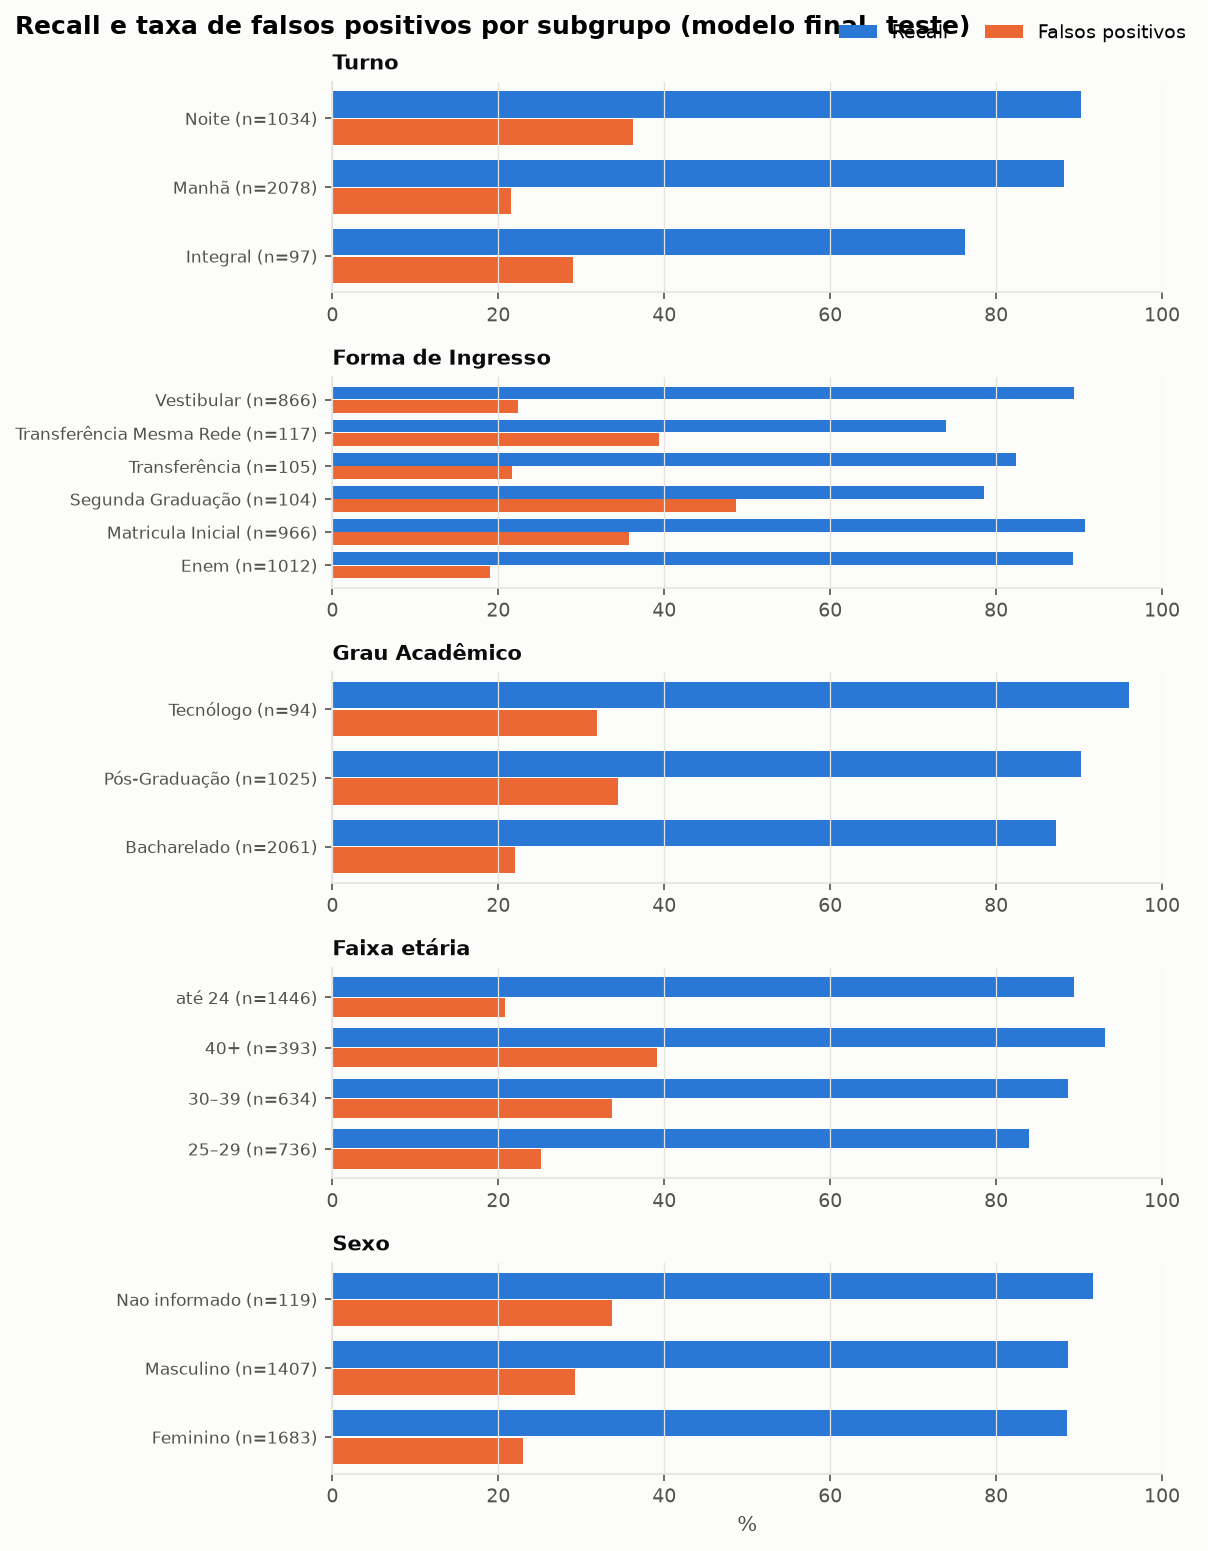

In [13]:
linhas = []
for attr, vals in A["equidade"]["final"]["limiar_recomendado"].items():
    for val, m in vals.items():
        if isinstance(m.get("n"), int):
            linhas.append({"atributo": attr, "grupo": val, **{k: m[k] for k in ("n", "taxa_evasao_real", "taxa_sinalizacao", "recall", "taxa_falsos_positivos")}})
eq = pd.DataFrame(linhas).set_index(["atributo", "grupo"])
display(eq)
display(Image(EVID / "risco_equidade_subgrupos.png", width=620))

**Leitura:**
- **Sexo**: recall praticamente igual entre feminino e masculino (~89%). A taxa de falsos positivos é maior entre homens (~29% vs ~23%), acompanhando a taxa real de evasão, que também é maior entre eles.
- **Turno**: a noite é mais sinalizada e tem mais falsos positivos, mas também evade mais; o recall fica parelho entre manhã e noite. O integral tem poucos alunos e recall menor.
- **Faixa etária**: sinalização e falsos positivos crescem com a idade, junto com a evasão real (40+ evade ~2× mais que até 24).
- **Forma de ingresso**: a maior diferença está em Segunda Graduação e Transferência Mesma Rede (grupos com ~100 alunos no teste e, por isso, mais ruidosos).

Nenhum grupo fica com recall muito abaixo dos demais. Onde há diferença de falsos positivos, ela segue diferenças reais de evasão; como um falso positivo aqui significa **um contato de apoio a mais** (nunca uma medida punitiva), o risco é baixo, mas a equipe deve acompanhar esses grupos.

XGBoost (sem restrição) nas três variantes, com a MESMA carga de contatos


,auc,pr_auc,recall,precisao,carga,lacuna_recall_Sexo,lacuna_recall_Turno,lacuna_recall_Faixa etária
completo_e1,0.932,0.839,0.916,0.468,0.383,0.009,0.122,0.081
sem_sensiveis,0.932,0.843,0.909,0.464,0.383,0.023,0.107,0.080
sem_sensiveis_sem_contatos,0.927,0.814,0.909,0.464,0.383,0.065,0.063,0.086


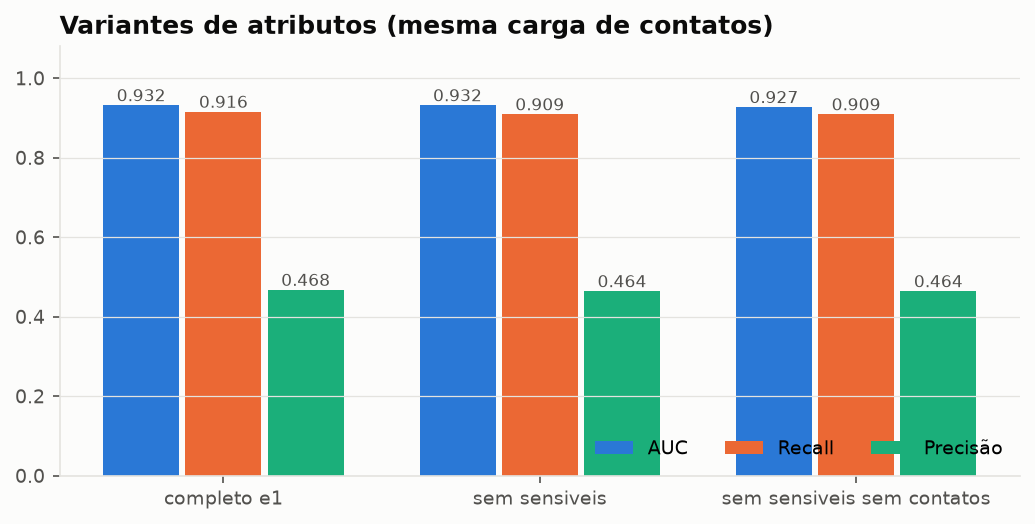

In [14]:
vv = pd.DataFrame({n: {**v["geral"], **{f"lacuna_recall_{k}": v["lacunas_entre_grupos"].get(k, {}).get("recall") for k in ("Sexo", "Turno", "Faixa etária")}}
                   for n, v in A["equidade"]["variantes_mesma_carga"].items()}).T
print("XGBoost (sem restrição) nas três variantes, com a MESMA carga de contatos")
display(vv)
display(Image(EVID / "risco_variantes_equidade.png", width=560))

**Achado:** retirar **Sexo e Estado Civil** não altera AUC, recall nem precisão com a mesma carga de contatos (variações na terceira casa decimal). A lacuna de recall entre os grupos de sexo vai de 0,9 para 2,3 p.p., ainda pequena. Ou seja, **esses atributos não trazem informação útil** que não esteja em outras variáveis; mantê-los só traria risco legal (LGPD, dado sensível) e de percepção de discriminação.

Retirar também os contatos (regra 5) aumenta essa lacuna para 6,5 p.p. no XGBoost livre. No **modelo final** (monotônico, tabela da seção anterior) ela fica em ~3 p.p., com recall de ~89% para feminino e masculino. É um ponto para acompanhar: se a base passar a separar contato ativo de pedido do estudante, os contatos ativos podem voltar.

**Recomendação:** versão final **sem Sexo e Estado Civil** e também **sem os contatos com o ASA** (regra 5). A idade fica como entrada, nunca como fator exibido, e a equidade por faixa etária continua monitorada a cada retreino.

## 6. Explicabilidade

- **Global:** contribuição média |SHAP| (TreeSHAP exato do XGBoost) e, para conferência independente, importância por permutação (queda de AUC no teste).
- **Por aluno:** `RiskModel.explicar(features)` devolve os fatores no formato `Fator` do contrato (`codigo`, `descricao`, `dimensao`, `direcao`, `peso`).

,|SHAP| médio,permutação (ΔAUC)
valor_total_periodo,1.222,2.539e-01
tempo_de_curso,0.498,5.360e-02
Idade,0.407,3.610e-02
total_parcelas,0.398,3.760e-02
total_semestres,0.349,2.400e-02
media_notas,0.272,4.400e-03
Grau Acadêmico,0.243,1.440e-02
Forma de Ingresso,0.185,7.600e-03
tendencia_notas,0.157,6.800e-03
atraso_medio_dias,0.152,3.800e-03


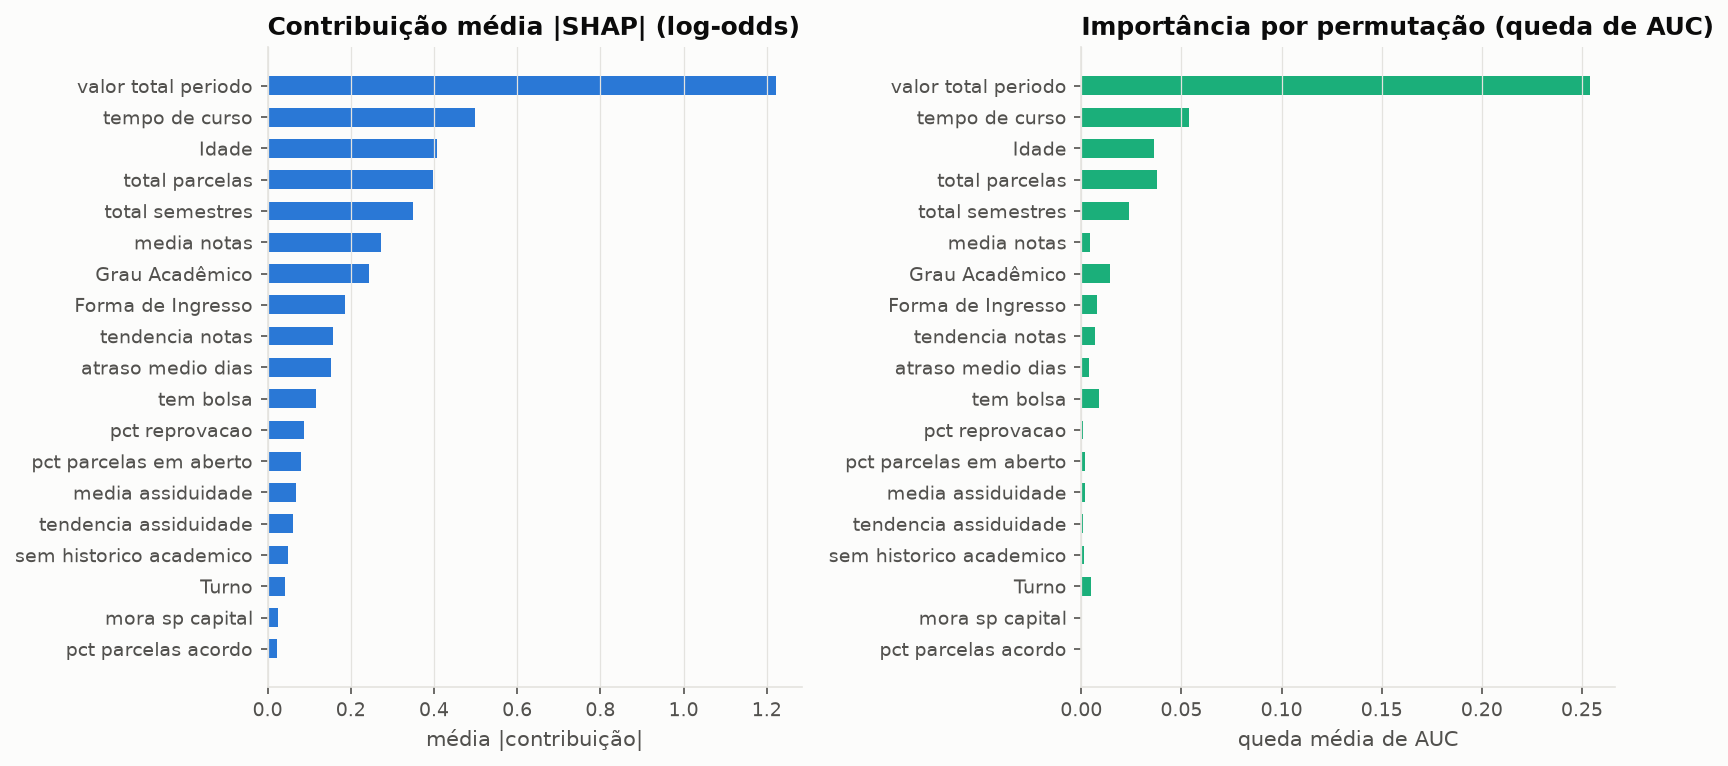

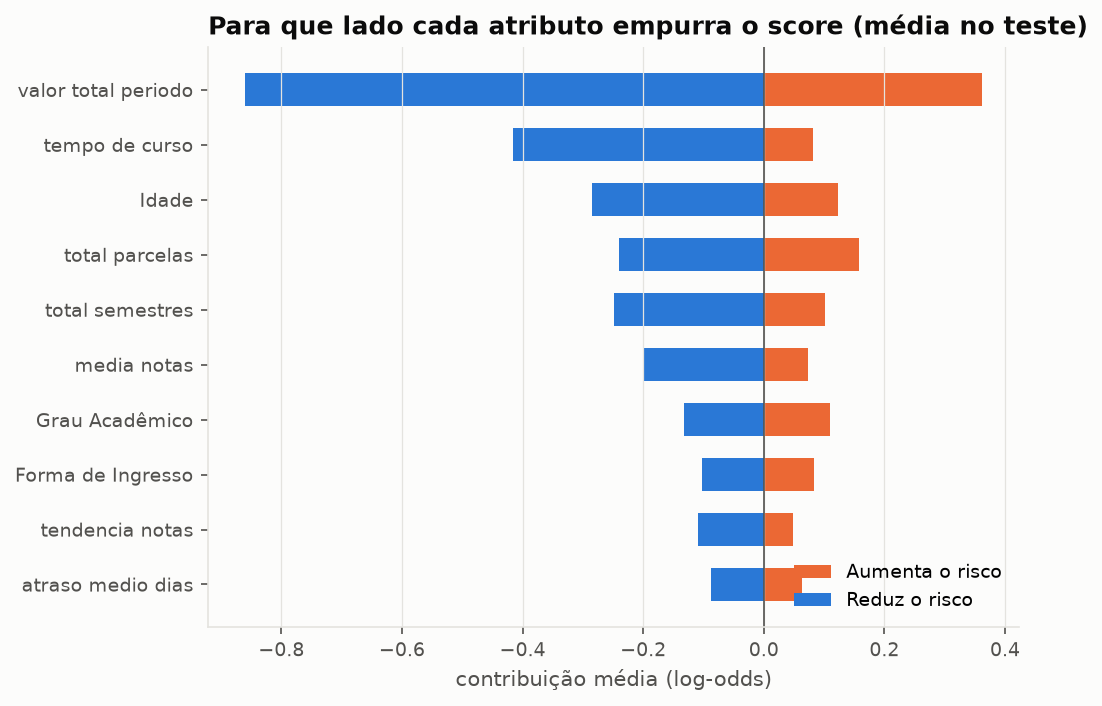

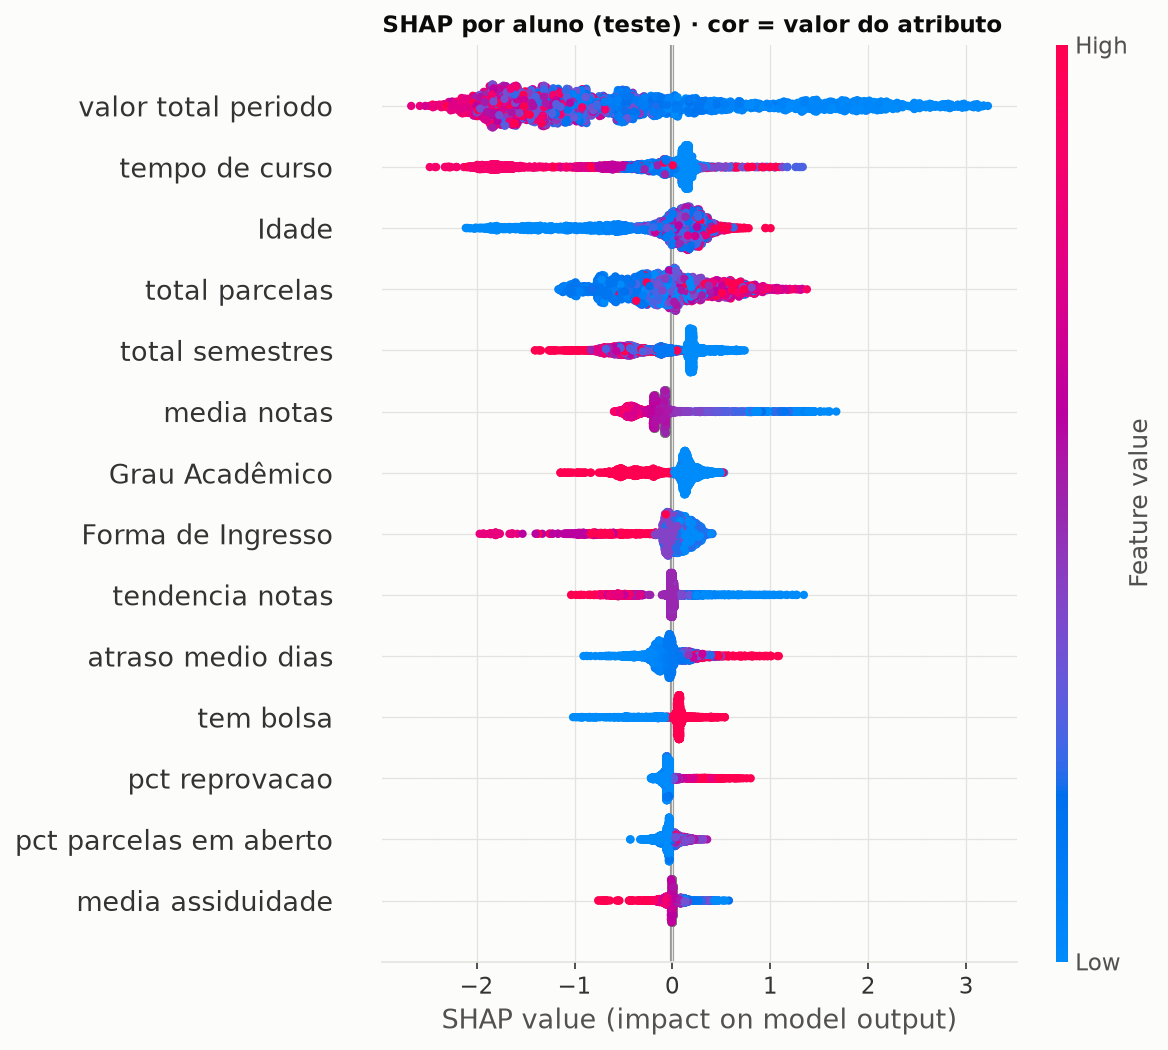

In [15]:
imp = pd.DataFrame({"|SHAP| médio": A["explicabilidade"]["media_abs_contribuicao"], "permutação (ΔAUC)": A["explicabilidade"]["importancia_permutacao_auc"]})
display(imp.sort_values("|SHAP| médio", ascending=False))
display(Image(EVID / "risco_importancia_global.png", width=820))
display(Image(EVID / "risco_direcao_fatores.png", width=560))
display(Image(EVID / "risco_shap_resumo.png", width=620))

**Leitura:** o **valor do período** domina com folga nas duas medidas, seguido de tempo de curso, total de parcelas, idade e semestres cursados; SHAP e permutação concordam no topo. As direções fazem sentido para o atendente: notas e frequência altas reduzem o risco; parcelas em aberto, atraso e reprovação só podem aumentá-lo (garantido pelas restrições).

Dois cuidados: (1) a **idade** pesa bastante. Ela nunca aparece como fator, mas influencia o score, por isso a equidade por faixa etária é monitorada (seção 5). Uma variante sem idade é o próximo teste se a equipe quiser reduzir ainda mais o uso de atributos pessoais. (2) O peso do valor do período e do tempo de curso reflete em parte o retrato pós-desfecho (quem saiu cedo pagou pouco e ficou pouco tempo).

### 6.1 Explicação de um aluno (exemplo **sintético**, não é um aluno real)

In [16]:
modelo = RiskModel.carregar(ML / "artifacts" / "risco_v2.joblib")
exemplo = A["explicabilidade"]["exemplo_sintetico"]["entrada"]
r = modelo.predict(exemplo)
print(f"probabilidade {r['probabilidade']:.2f} · categoria {r['categoria']} · score por dimensão {r['score']}")
display(pd.DataFrame(r["fatores"]))
print("Recomendação:", r["recomendacao"]); print(r["aviso"])
from risco.modelo import explicar
assert explicar(exemplo) == r["fatores"]

probabilidade 0.91 · categoria vermelho · score por dimensão {'geral': 0.912, 'financeiro': 0.4287, 'academico': 0.5801, 'relacionamento': 0.203}


,codigo,descricao,dimensao,direcao,peso
0,valor_periodo,Valor do período abaixo da mediana dos alunos,financeira,aumenta,0.364
1,media_notas,Média de notas 41/100,academica,aumenta,0.206
2,semestres_cursados,2 semestres cursados,academica,reduz,0.126
3,total_parcelas,12 parcelas no contrato,financeira,reduz,0.119
4,frequencia,Frequência média de 63%,academica,aumenta,0.105
5,atraso_pagamentos,Atraso médio de 21 dias nos pagamentos,financeira,aumenta,0.080


Recomendação: Contato prioritário. Oferecer conversa sobre opções de apoio financeiro (bolsas, renegociação, auxílio emergencial).
Apoio à decisão. Nenhuma ação deve ser tomada sem avaliação humana.


**Leitura:** o atendente vê frases prontas ("Média de notas 41/100", "Atraso médio de 21 dias nos pagamentos"), a dimensão (financeira, acadêmica, relacionamento), a direção e o peso relativo. Atributos sensíveis (sexo, estado civil, idade) **nunca** aparecem como fator, e contatos com o ASA nunca aparecem como fator que aumenta o risco. A recomendação é sempre de apoio, guiada pela dimensão do principal fator, e vem com o aviso de que nenhuma ação dispensa avaliação humana.

**Score por dimensão:** probabilidade considerando só os desvios daquela dimensão em relação ao aluno médio. Serve para o atendente ver *onde* está o problema, não é uma segunda probabilidade de evasão.

## 7. Análise de erros

Perfil (medianas e proporções agregadas) de verdadeiros positivos (VP), falsos negativos (FN), falsos positivos (FP) e verdadeiros negativos (VN) no corte recomendado.

In [17]:
pe = A["erros"]["perfil"]
print("Quantidade:", pe["n"])
display(pd.DataFrame(pe["medianas"]).T[["media_notas", "media_assiduidade", "pct_parcelas_em_aberto", "total_parcelas", "valor_total_periodo", "tempo_de_curso", "total_semestres", "Idade"]])
display(pd.Series(pe["pct_sem_notas_e_frequencia"], name="% sem notas e frequência").to_frame())
for i, o in enumerate(A["erros"]["observacoes"], 1):
    display(Markdown(f"**{i}.** {o}"))

Quantidade: {'VP': 557, 'FN': 71, 'FP': 673, 'VN': 1908}


,media_notas,media_assiduidade,pct_parcelas_em_aberto,total_parcelas,valor_total_periodo,tempo_de_curso,total_semestres,Idade
FN,65.04,91.07,0.00,35.0,38298.00,1.0,3.0,28.0
FP,0.00,0.00,0.02,18.0,12800.10,0.0,0.0,27.0
VN,66.12,92.24,0.00,31.0,43566.66,3.0,3.0,24.0
VP,0.00,0.00,0.00,18.0,5131.99,0.0,0.0,28.0


,% sem notas e frequência
FN,0.394
FP,0.584
VN,0.279
VP,0.691


**1.** Falsos negativos (evadiram sem ser sinalizados) parecem alunos que ficam: nota mediana 65 (VN 66), frequência 91% (VN 92%), 3 semestres cursados (VN 3). É a evasão de quem estava bem: os dados disponíveis não têm sinal para ela.

**2.** Falsos positivos parecem os verdadeiros positivos: 58% deles não têm nenhuma nota nem frequência lançadas (VP 69%, VN 28%), tempo de curso mediano 0 e valor do período mediano R$ 12.800 (VP R$ 5.132, VN R$ 43.567). São sobretudo ingressantes sem histórico; para eles, um contato de acolhimento tem custo baixo e não é perdido.

**3.** Pós-Graduação responde por 37% dos falsos negativos. Recall por grau: Bacharelado 87%, Pós-Graduação 90%, Tecnólogo 96%. Onde o recall é menor, vale uma rotina própria (ex.: contato no 1º mês), independente do score.

**4.** Veteranos escapam mais: os FN têm mediana de 35 parcelas contra 18 dos VP. Recalcular o score todo mês, com notas e frequência do mês corrente, é o caminho para pegar quem piora no meio do curso.

**5.** A base é um retrato tirado depois do desfecho: quem evadiu tem mediana 0 de parcelas em aberto (as parcelas são encerradas) e 69% dos VP não têm notas lançadas. Isso infla a AUC e foi o motivo das restrições monotônicas. Antes de confiar no número absoluto, a v3 precisa de features com data de corte anterior à evasão.

## 8. Escolha final

In [18]:
mv = json.loads((ML / "artifacts" / "MODEL_VERSION.json").read_text())
print(json.dumps({k: mv[k] for k in ("versao", "algoritmo", "calibracao", "conjunto_features", "features_removidas", "limiares_ativos", "limiares_recomendados", "metricas_teste_limiar_ativo", "metricas_teste_limiar_recomendado")}, ensure_ascii=False, indent=1))
for j in mv["justificativa"]:
    display(Markdown("- " + j))

{
 "versao": "risco-2.0.0",
 "algoritmo": "XGBoost monotônico",
 "calibracao": "isotonic",
 "conjunto_features": "sem_sensiveis_sem_contatos+derivadas",
 "features_removidas": [
  "Sexo",
  "Estado Civil",
  "total_contatos",
  "dias_desde_ultimo_contato"
 ],
 "limiares_ativos": {
  "amarelo": 0.3,
  "vermelho": 0.6
 },
 "limiares_recomendados": {
  "amarelo": 0.1,
  "vermelho": 0.6
 },
 "metricas_teste_limiar_ativo": {
  "auc": 0.9129,
  "pr_auc": 0.755,
  "brier": 0.083,
  "recall": 0.758,
  "precisao": 0.6355,
  "f1": 0.6914,
  "pct_sinalizados": 0.2334
 },
 "metricas_teste_limiar_recomendado": {
  "auc": 0.9129,
  "pr_auc": 0.755,
  "brier": 0.083,
  "recall": 0.8869,
  "precisao": 0.4528,
  "f1": 0.5996,
  "pct_sinalizados": 0.3833
 }
}


- Na validação cruzada do treino (5 folds), as árvores superam a logística por ~0,10 de AUC (RL 0.835, RF 0.938, XGBoost 0.935). RF e XGBoost empatam (diferença < 0,005); fica o XGBoost, que explica cada aluno de forma exata (TreeSHAP nativo) e gera um artefato muito menor. O teste não foi usado para escolher.

- Restrições monotônicas (mais parcelas em aberto/atraso/reprovação → mais risco; mais nota/frequência → menos risco) custam 0.014 de AUC na CV (0.929 → 0.915). Sem elas, o modelo aprende artefatos do retrato pós-desfecho (ex.: 0% de parcelas em aberto associado a mais evasão) e mostraria ao atendente fatores contraditórios. Aceitas por custarem menos que o limite definido (0,03).

- Sexo e Estado Civil retirados: perda de AUC < 0,01 na CV e as lacunas de recall/FPR entre grupos não pioram.

- total_contatos e dias_desde_ultimo_contato retirados (regra 5): a base não separa pedidos do estudante de contatos ativos do ASA, então procurar o ASA poderia mudar o score.

- Probabilidade calibrada (isotonic, Brier 0.083 no teste): o score se lê como chance de evasão.

**Versão recomendada: `risco-2.0.0` — XGBoost monotônico, calibrado (isotônica), sem Sexo, Estado Civil e contatos, com faixas Amarelo ≥ 0,10 / Vermelho ≥ 0,60.**

Por quê, em uma frase: com a mesma equipe, o ASA alcança mais evasões com menos contatos (recall ~76% contatando 23% no corte do contrato, ou ~89% contatando 38% no corte recomendado, contra 77% contatando 36% na E1), com probabilidades que significam o que dizem e explicações que nunca contradizem o bom senso, sem usar atributos sensíveis.

### Limitações
- **Retrato pós-desfecho:** parte das features reflete a evasão já ocorrida (parcelas encerradas, notas não lançadas). A AUC absoluta é otimista; a v3 precisa de features com data de corte anterior ao desfecho.
- **Rótulo sem janela temporal** (pendência da E1, ainda não confirmada com o ASA).
- **Contatos fora do modelo** até a base distinguir contato ativo de pedido do estudante (regra 5).
- **Subgrupos pequenos** (Integral, Tecnólogo, Segunda Graduação, Transferências) têm métricas ruidosas e precisam de monitoramento a cada retreino.